# Step 1

418 patients in total having PBC - Primary Biliary Cholangitis. 312 patients took part in a randomised trial and each of them was assigned at random to one of two treatment groups (d-penicillamine (real drug) vs placebo). The other 106 patients didn't take part in the trial.

The goal is to predict survival.

In [43]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import numpy as np
from lifelines import KaplanMeierFitter
from lifelines.plotting import add_at_risk_counts
from lifelines.statistics import logrank_test

### Dataset

In [2]:
DATA = "pbc.csv"
data = pd.read_csv(DATA).drop(columns="Unnamed: 0")

print(data.shape)
data.head()

(418, 20)


,id,time,status,trt,age,sex,ascites,hepato,spiders,edema,bili,chol,albumin,copper,alk.phos,ast,trig,platelet,protime,stage
0,1,400,2,1.0,58.765229,f,1.0,1.0,1.0,1.0,14.5,261.0,2.60,156.0,1718.0,137.95,172.0,190.0,12.2,4.0
1,2,4500,0,1.0,56.446270,f,0.0,1.0,1.0,0.0,1.1,302.0,4.14,54.0,7394.8,113.52,88.0,221.0,10.6,3.0
2,3,1012,2,1.0,70.072553,m,0.0,0.0,0.0,0.5,1.4,176.0,3.48,210.0,516.0,96.10,55.0,151.0,12.0,4.0
3,4,1925,2,1.0,54.740589,f,0.0,1.0,1.0,0.5,1.8,244.0,2.54,64.0,6121.8,60.63,92.0,183.0,10.3,4.0
4,5,1504,1,2.0,38.105407,f,0.0,1.0,1.0,0.0,3.4,279.0,3.53,143.0,671.0,113.15,72.0,136.0,10.9,3.0


### Define the events and trial indicators

- `time`: days from registration until death, transplant or the end of follow-up (July 1986);
- `status`: 0 = censored (alive at the end of follow-up), 1 = liver transplant, 2 = death;
- `event`: the outcome used in the analysis, 1 = death (`status` = 2), 0 = censored;
- patients who received a liver transplant are treated as censored on the day of the transplant: we know they were alive until then, but after the transplant their survival no longer reflects the course of PBC. For this reason, they get `event` = 0;
- `trt`: 1 = D-penicillamine, 2 = placebo. It is missing for the 106 patients who were not part of the trial (ids 313–418).

In [3]:
data["event"] = (data["status"] == 2).astype(int)
data["trial"] = data["trt"].notna().astype(int)
data["arm"] = data["trt"].map({1: "D-penicillamine", 2: "Placebo"})
data["female"] = (data["sex"] == "f").astype(int)
data["time_years"] = data["time"] / 365.25 # average year length, counting leap years

print("Status:", data["status"].value_counts().sort_index().rename({0: "censored", 1: "transplant", 2: "death"}).to_dict())
print("Trial vs non-trial:", data["trial"].value_counts().rename({1: "trial", 0: "non-trial"}).to_dict())
print("Trial only:", data["arm"].value_counts().to_dict())

Status: {'censored': 232, 'transplant': 25, 'death': 161}
Trial vs non-trial: {'trial': 312, 'non-trial': 106}
Trial only: {'D-penicillamine': 158, 'Placebo': 154}


In [4]:
data.head()

,id,time,status,trt,age,sex,ascites,hepato,spiders,edema,...,ast,trig,platelet,protime,stage,event,trial,arm,female,time_years
0,1,400,2,1.0,58.765229,f,1.0,1.0,1.0,1.0,...,137.95,172.0,190.0,12.2,4.0,1,1,D-penicillamine,1,1.095140
1,2,4500,0,1.0,56.446270,f,0.0,1.0,1.0,0.0,...,113.52,88.0,221.0,10.6,3.0,0,1,D-penicillamine,1,12.320329
2,3,1012,2,1.0,70.072553,m,0.0,0.0,0.0,0.5,...,96.10,55.0,151.0,12.0,4.0,1,1,D-penicillamine,0,2.770705
3,4,1925,2,1.0,54.740589,f,0.0,1.0,1.0,0.5,...,60.63,92.0,183.0,10.3,4.0,1,1,D-penicillamine,1,5.270363
4,5,1504,1,2.0,38.105407,f,0.0,1.0,1.0,0.0,...,113.15,72.0,136.0,10.9,3.0,0,1,Placebo,1,4.117728


### Split the variables into groups

The variables are split into:
- `demographics`: who the patient is;
- `clinical history`: signs the doctor finds examining the patient without making any test;
- `lab test`;
- `histology`: disease stage from a liver biopsy. It is kept separate as it is neither a finding from a simple examination nor a routine lab test.

In [5]:
groups = {
    "demographics": ["age", "female"],
    "clinical history": ["ascites", "hepato", "spiders", "edema"],
    "labs": ["bili", "albumin", "protime", "alk.phos", "ast", "chol", "trig", "copper", "platelet"],
    "histology (biopsy)": ["stage"],
}

labs = groups["labs"]
patient_vars = groups["demographics"] + groups["clinical history"]

for k, v in groups.items():
    print(f"{k:20s} {v}")

demographics         ['age', 'female']
clinical history     ['ascites', 'hepato', 'spiders', 'edema']
labs                 ['bili', 'albumin', 'protime', 'alk.phos', 'ast', 'chol', 'trig', 'copper', 'platelet']
histology (biopsy)   ['stage']


### Which variables need log-transformation?

We focus only on continuous variables, leaving unchanged binary variables and ordered ones. So, we exclude the gender, ascites, hepato, spiders, edema and stage. This leaves us with only the age and the labs variables.

In [6]:
data.head(2)

,id,time,status,trt,age,sex,ascites,hepato,spiders,edema,...,ast,trig,platelet,protime,stage,event,trial,arm,female,time_years
0,1,400,2,1.0,58.765229,f,1.0,1.0,1.0,1.0,...,137.95,172.0,190.0,12.2,4.0,1,1,D-penicillamine,1,1.095140
1,2,4500,0,1.0,56.446270,f,0.0,1.0,1.0,0.0,...,113.52,88.0,221.0,10.6,3.0,0,1,D-penicillamine,1,12.320329


In [16]:
continuous_variables = ["age"] + labs
print(data[continuous_variables].describe().T.round(2))

          count     mean      std     min     25%      50%      75%       max
age       418.0    50.74    10.45   26.28   42.83    51.00    58.24     78.44
bili      418.0     3.22     4.41    0.30    0.80     1.40     3.40     28.00
albumin   418.0     3.50     0.42    1.96    3.24     3.53     3.77      4.64
protime   416.0    10.73     1.02    9.00   10.00    10.60    11.10     18.00
alk.phos  312.0  1982.66  2140.39  289.00  871.50  1259.00  1980.00  13862.40
ast       312.0   122.56    56.70   26.35   80.60   114.70   151.90    457.25
chol      284.0   369.51   231.94  120.00  249.50   309.50   400.00   1775.00
trig      282.0   124.70    65.15   33.00   84.25   108.00   151.00    598.00
copper    310.0    97.65    85.61    4.00   41.25    73.00   123.00    588.00
platelet  407.0   257.02    98.33   62.00  188.50   251.00   318.00    721.00


Show raw vs log-transformed continuous variables.

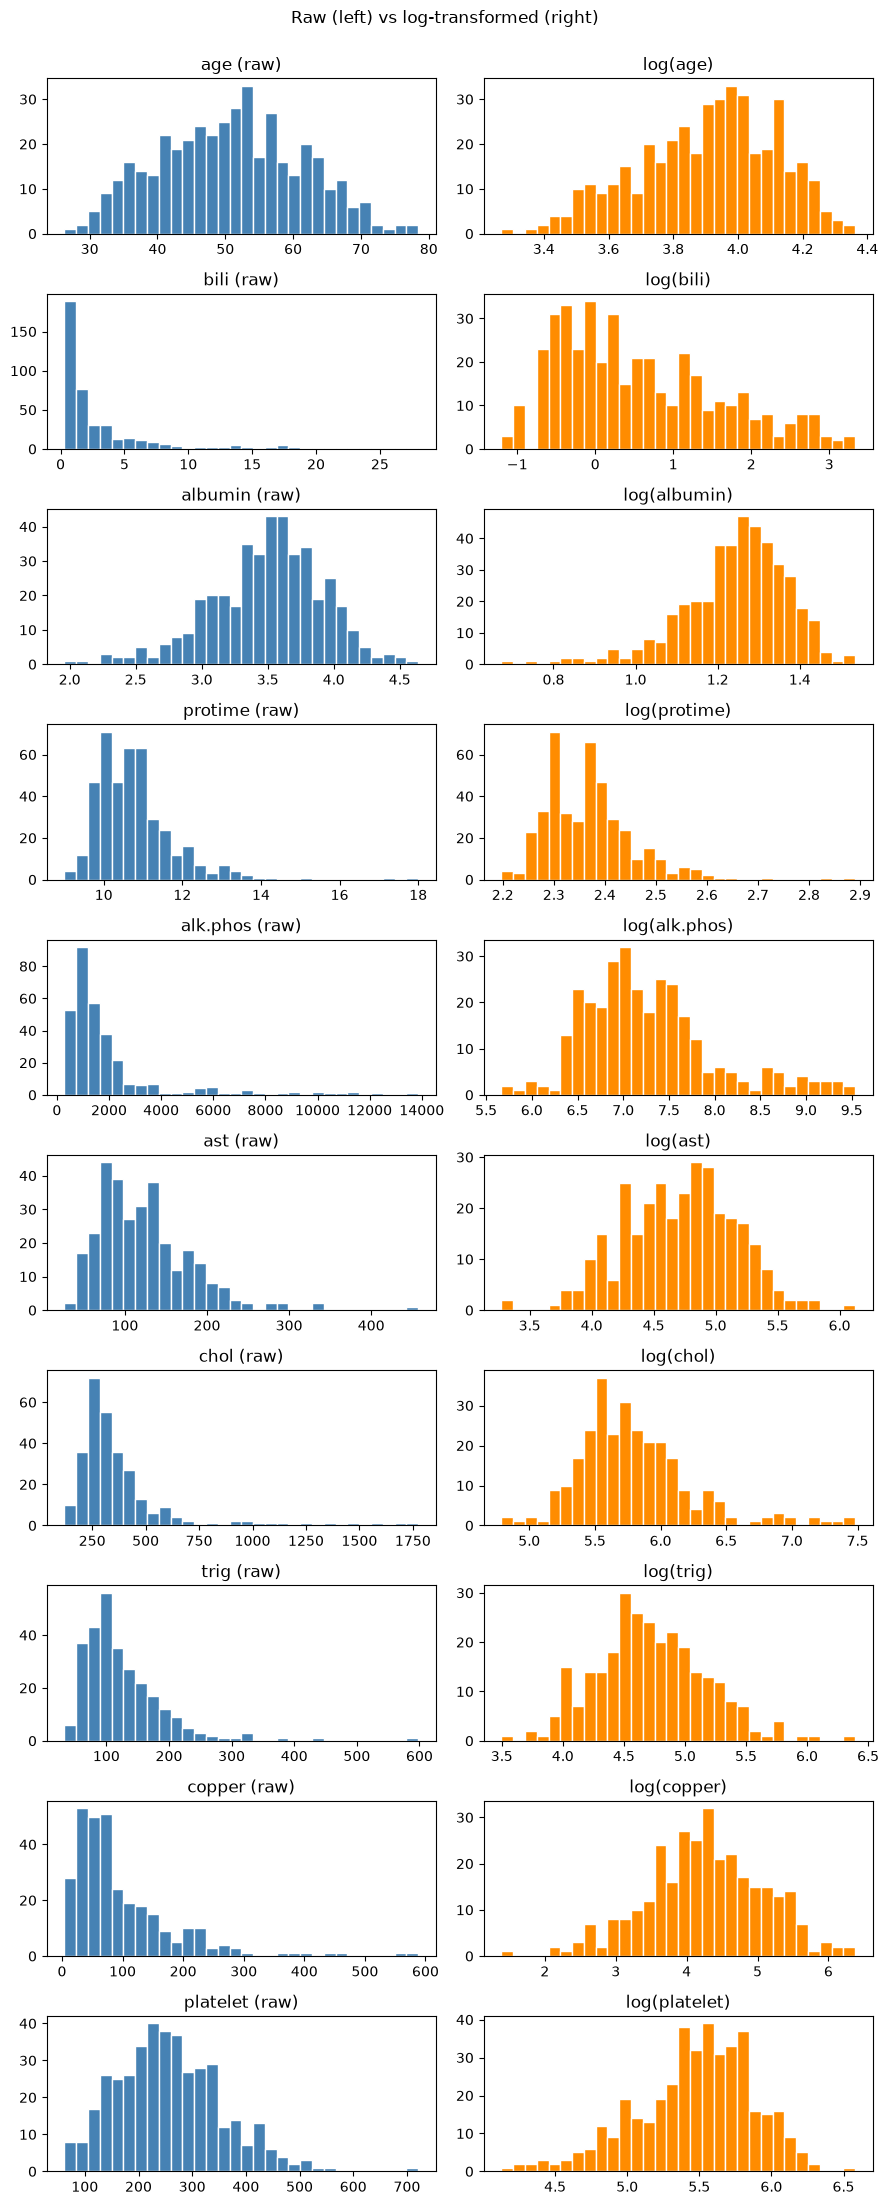

In [ ]:
n = len(continuous_variables)
fig, axes = plt.subplots(n, 2, figsize=(9, 2.2 * n))
for i, v in enumerate(continuous_variables):
    x = data[v].dropna()
    axes[i, 0].hist(x, bins=30, color="steelblue", edgecolor="white")
    axes[i, 0].set_title(f"{v} (raw)")
    axes[i, 1].hist(np.log(x), bins=30, color="darkorange", edgecolor="white")
    axes[i, 1].set_title(f"log({v})")
plt.suptitle("Raw (left) vs log-transformed (right)", y=1.0)
plt.tight_layout()
plt.show();

We decided to log-transform based on visual inspection.

In [23]:
to_log = ["bili", "chol", "copper", "alk.phos", "ast", "trig", "protime"]

for v in to_log:
    data["log_" + v] = np.log(data[v])

continuous_model = ["log_" + v if v in to_log else v for v in continuous_variables]
lab_model = ["log_" + v if v in to_log else v for v in labs]

print("Log-transformed:", to_log)
print("Continuous variables used in models:", continuous_model)
print("Lab variables used in models:", lab_model)

Log-transformed: ['bili', 'chol', 'copper', 'alk.phos', 'ast', 'trig', 'protime']
Continuous variables used in models: ['age', 'log_bili', 'albumin', 'log_protime', 'log_alk.phos', 'log_ast', 'log_chol', 'log_trig', 'log_copper', 'platelet']
Lab variables used in models: ['log_bili', 'albumin', 'log_protime', 'log_alk.phos', 'log_ast', 'log_chol', 'log_trig', 'log_copper', 'platelet']


Show the log-transformed variables:

              count    mean    std    min     25%     50%     75%     max
age           418.0   50.74  10.45  26.28   42.83   51.00   58.24   78.44
log_bili      418.0    0.57   1.02  -1.20   -0.22    0.34    1.22    3.33
albumin       418.0    3.50   0.42   1.96    3.24    3.53    3.77    4.64
log_protime   416.0    2.37   0.09   2.20    2.30    2.36    2.41    2.89
log_alk.phos  312.0    7.27   0.72   5.67    6.77    7.14    7.59    9.54
log_ast       312.0    4.71   0.45   3.27    4.39    4.74    5.02    6.13
log_chol      284.0    5.80   0.44   4.79    5.52    5.73    5.99    7.48
log_trig      282.0    4.72   0.45   3.50    4.43    4.68    5.02    6.39
log_copper    310.0    4.26   0.83   1.39    3.72    4.29    4.81    6.38
platelet      407.0  257.02  98.33  62.00  188.50  251.00  318.00  721.00


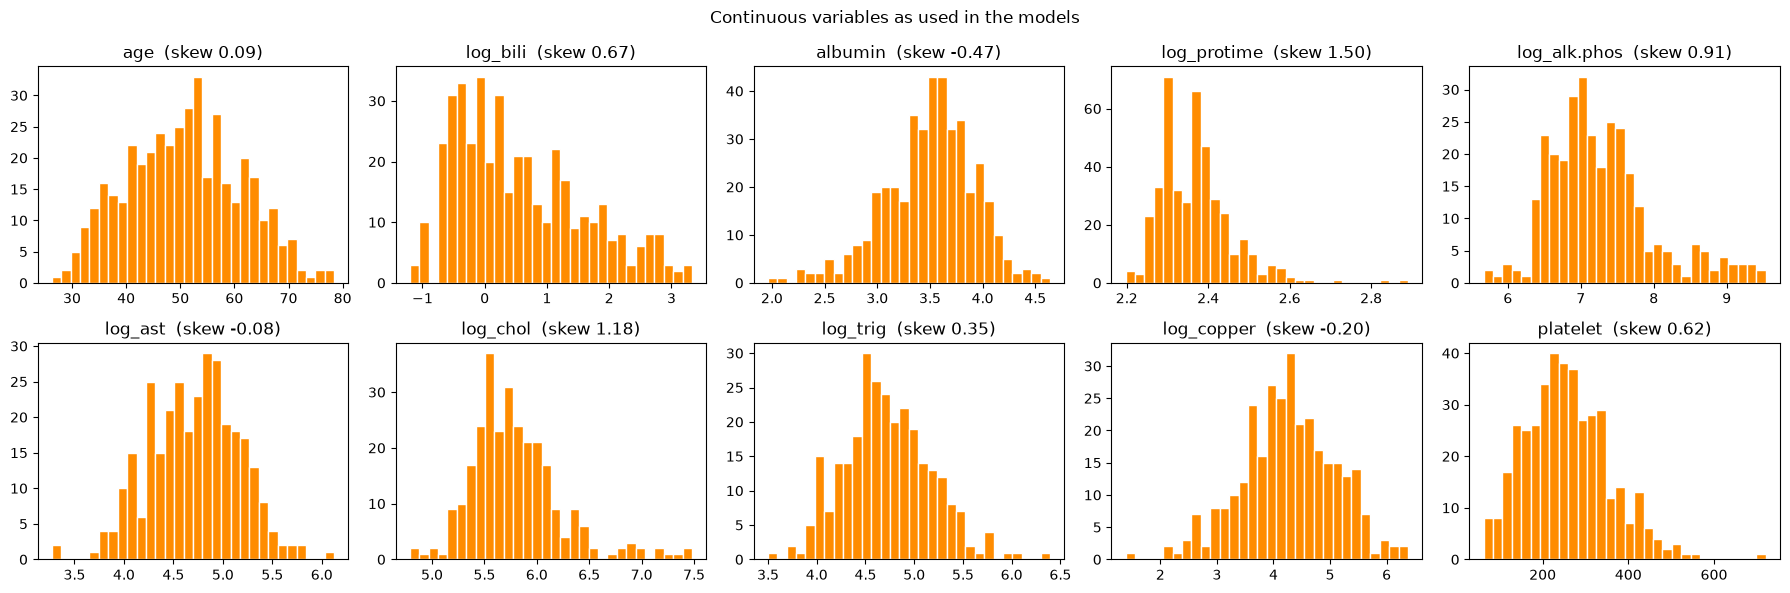

In [25]:
print(data[continuous_model].describe().T.round(2))

n = len(continuous_model)
fig, axes = plt.subplots(2, (n + 1) // 2, figsize=(18, 6))
for ax, v in zip(axes.ravel(), continuous_model):
    x = data[v].dropna()
    ax.hist(x, bins=30, color="darkorange", edgecolor="white")
    ax.set_title(f"{v}  (skew {stats.skew(x):.2f})")
for ax in axes.ravel()[n:]:
    ax.axis("off")
plt.suptitle("Continuous variables as used in the models")
plt.tight_layout()
plt.show();

Note that both `log_chol` and especially `log_protime` are still skewed after being log-transformed.

A Cox model assumes each variable has a linear effect on the log-hazard. For the lab variables with a long right tail, a few very high values would dominate the fit. That's the reason why we log transformed the variables. Standardizing is not relevant for the methods we intend to perform expect for the Ridge and Lasso regularization. 

CHECK

### An overview on missing data

In [27]:
model_vars = patient_vars + labs + ["stage"]
miss = pd.DataFrame({
    "all (n=418) %": data[model_vars].isna().mean() * 100,
    "trial (n=312) %": data.loc[data.trial == 1, model_vars].isna().mean() * 100,
    "non-trial (n=106) %": data.loc[data.trial == 0, model_vars].isna().mean() * 100,
}).round(1)
miss[miss.iloc[:, 0] > 0].sort_values("all (n=418) %", ascending=False)

,all (n=418) %,trial (n=312) %,non-trial (n=106) %
trig,32.5,9.6,100.0
chol,32.1,9.0,100.0
copper,25.8,0.6,100.0
ascites,25.4,0.0,100.0
hepato,25.4,0.0,100.0
spiders,25.4,0.0,100.0
alk.phos,25.4,0.0,100.0
ast,25.4,0.0,100.0
platelet,2.6,1.3,6.6
stage,1.4,0.0,5.7


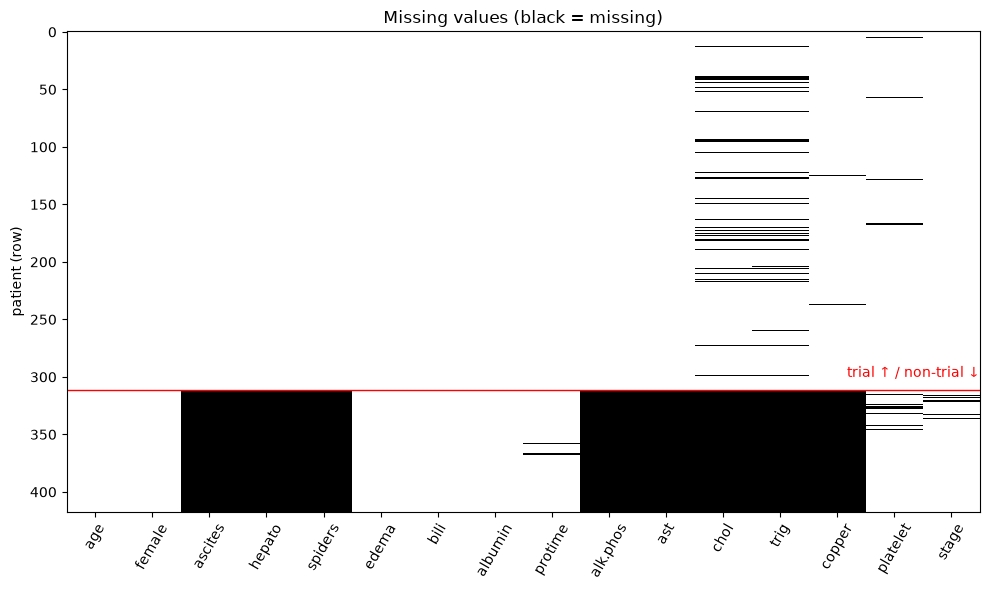

In [29]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.imshow(data[model_vars].isna().values, aspect="auto", cmap="Greys", interpolation="none")
ax.set_xticks(range(len(model_vars))); ax.set_xticklabels(model_vars, rotation=60)
ax.axhline(311.5, color="red", lw=1); ax.text(len(model_vars) - 0.5, 300, "trial ↑ / non-trial ↓", color="red", ha="right")
ax.set_ylabel("patient (row)"); ax.set_title("Missing values (black = missing)")
plt.tight_layout()
plt.show();

For non-trial patients, 8 variables are missing for all of them. This is by design as these patients only agreed on basic measurements.

For trial patients, only few values are missing.

LOOK MORE INTO HOW MISSING VALUES OCCUR IN THE TRIAL PATIENTS

### Which trial patients samples to keep?

In [34]:
trial = data[data.trial == 1].copy()
cc_data = trial.dropna(subset=patient_vars + labs + ["stage"]).copy()
print(f"Trial patients: {len(trial)} ({trial.event.sum()} deaths)")
print(f"Complete cases: {len(cc_data)} ({cc_data.event.sum()} deaths)")
print("Arms in non-complete cases:", trial.arm.value_counts().to_dict())
print("Arms in complete cases:", cc_data.arm.value_counts().to_dict())

km_data = cc_data

Trial patients: 312 (125 deaths)
Complete cases: 276 (111 deaths)
Arms in non-complete cases: {'D-penicillamine': 158, 'Placebo': 154}
Arms in complete cases: {'Placebo': 140, 'D-penicillamine': 136}


The difference in the placebo vs D-penicillamine between non-complete and complete cases is not significant (CHECK MORE SCIENTIFICALLY). Therefore, from here on we use only the 276 trial patients with no missing values. Using the same patients for every model means that any difference between models is caused by the variables, not by a change in which patients are included. The Kaplan–Meier curves and the log-rank test also use these 276 patients, so their conclusion (that treatment can be ignored) applies to exactly the patients we model.

### Comparison of the two arms

Trial patients were assigned to the two different arms at random. For this reason, the two groups should be similar before treatment. If they are, comparing their survival directly is fair.

We used the Mann-Whitney test for continuous variables, chi-square for binary and categorical variables.

In [35]:
def table1(d, group="arm"):
    rows = []
    g1, g2 = d[group].dropna().unique()
    for v in ["age", "female", "ascites", "hepato", "spiders", "edema", "stage"] + labs:
        a, b = d.loc[d[group] == g1, v].dropna(), d.loc[d[group] == g2, v].dropna()
        if d[v].nunique() <= 4: # binary / ordinal -> proportions or chi-square
            p = stats.chi2_contingency(pd.crosstab(d[group], d[v]))[1]
            s1, s2 = f"{a.mean():.2f}", f"{b.mean():.2f}"
        else: # continuous -> median [IQR], Mann-Whitney
            p = stats.mannwhitneyu(a, b).pvalue
            s1 = f"{a.median():.2f} [{a.quantile(.25):.2f}-{a.quantile(.75):.2f}]"
            s2 = f"{b.median():.2f} [{b.quantile(.25):.2f}-{b.quantile(.75):.2f}]"
        rows.append({"variable": v, g1: s1, g2: s2, "p": round(p, 3)})
    return pd.DataFrame(rows).set_index("variable")

print("Binary/ordinal: mean (= proportion for 0/1). Continuous: median [IQR].")
table1(km_data)

Binary/ordinal: mean (= proportion for 0/1). Continuous: median [IQR].


,D-penicillamine,Placebo,p
variable,,,
age,51.70 [42.64-58.81],47.95 [41.39-55.58],0.035
female,0.85,0.90,0.314
ascites,0.08,0.06,0.588
hepato,0.47,0.56,0.188
spiders,0.29,0.29,0.983
edema,0.12,0.09,0.490
stage,2.97,3.11,0.262
bili,1.45 [0.90-3.42],1.30 [0.70-3.60],0.940
albumin,3.55 [3.20-3.79],3.54 [3.35-3.76],0.656


The arms are similar for all variables except `age`. The D-penicillamine group is about 4 years older than the placebo one. The significant difference between the two is supported by the only p-value <= 0.05. Random assignment can produce these differences by chance. However, it is important to keep in mind as age increases the risk of death.

### Kaplan-Meiers curves

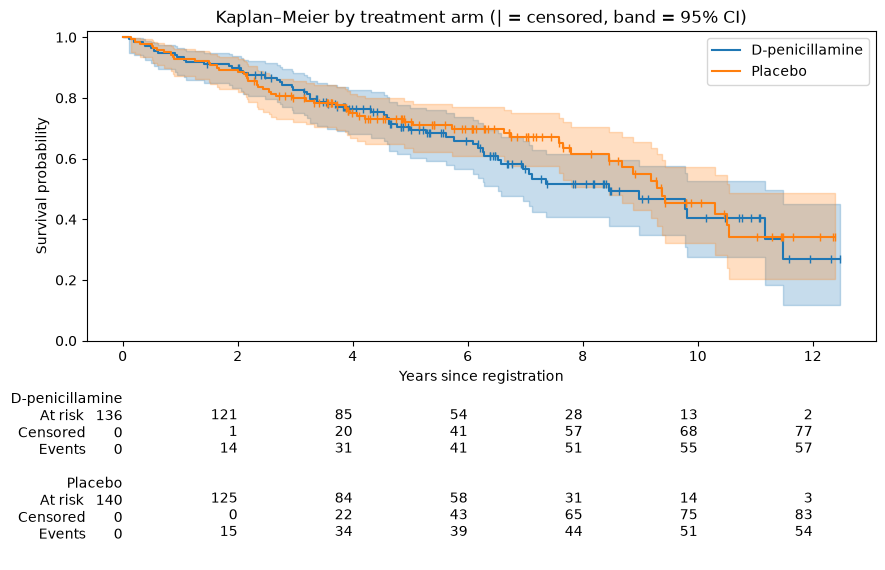

In [ ]:
fig, ax = plt.subplots(figsize=(9, 6))
fitters = {}
for arm, g in km_data.groupby("arm"):
    kmf = KaplanMeierFitter(label=arm)
    kmf.fit(g["time_years"], event_observed=g["event"])
    kmf.plot_survival_function(ax=ax, ci_show=True, show_censors=True,
                               censor_styles={"marker": "|", "ms": 6})
    fitters[arm] = kmf

ax.set_xlabel("Years since registration")
ax.set_ylabel("Survival probability")
ax.set_title("Kaplan–Meier by treatment arm (| = censored, band = 95% CI)")
ax.set_ylim(0, 1.02)
add_at_risk_counts(*fitters.values(), ax=ax) # number-at-risk table under the plot
plt.tight_layout()
plt.show()

In [42]:
for arm, kmf in fitters.items():
    print(f"{arm:16s} median survival {kmf.median_survival_time_:5.2f} y | "
          f"S(5y) = {kmf.predict(5):.2f} | S(10y) = {kmf.predict(10):.2f}")

for arm, kmf in fitters.items():
    print(f"\n{arm}")
    print(kmf.event_table.head(10))

D-penicillamine  median survival  8.45 y | S(5y) = 0.70 | S(10y) = 0.40
Placebo          median survival  9.39 y | S(5y) = 0.72 | S(10y) = 0.45

D-penicillamine
          removed  observed  censored  entrance  at_risk
event_at                                                
0.000000        0         0         0       136      136
0.112252        1         1         0         0      136
0.194387        1         1         0         0      135
0.358658        1         1         0         0      134
0.383299        1         1         0         0      133
0.490075        1         1         0         0      132
0.542094        1         1         0         0      131
0.610541        1         1         0         0      130
0.914442        1         1         0         0      129
0.952772        1         1         0         0      128

Placebo
          removed  observed  censored  entrance  at_risk
event_at                                                
0.000000        0         0     

### Log-rank test

In [44]:
drug = km_data[km_data["arm"] == "D-penicillamine"]
placebo = km_data[km_data["arm"] == "Placebo"]

lr = logrank_test(drug["time"], placebo["time"],
                  event_observed_A=drug["event"],
                  event_observed_B=placebo["event"])

print(f"Log-rank test: chi2 = {lr.test_statistic:.3f}, p = {lr.p_value:.3f}")

Log-rank test: chi2 = 0.405, p = 0.525


A large p-value means that the data give no evidence of a difference between the arms. It does not prove that there is no effect; in fact, a small effect of the drug could exist and remain undetected with this number of deaths.